# 03 — Figures

- **Fig 1** — the central map: change in the county price-to-income ratio, 2015–19 → 2020–24, continental US.
- **Fig 2** — the "why" chart: that change against population growth, binned means over the county cloud.

Both are saved to `results/figures/` and embedded in the post from there.

In [4]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

from plot_style import apply_style, COLORS, SITE, MAP_BINS, MAP_LABELS, MAP_COLORS, source_note

ROOT = Path.cwd().parent
PROCESSED = ROOT / "data" / "processed"
TABLES = ROOT / "results" / "tables"
FIGURES = ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
apply_style()

gdf = gpd.read_file(PROCESSED / "counties.gpkg", layer="counties")
conus = gdf.loc[gdf["conus"].fillna(False).astype(bool)].copy()
states = conus.dissolve("STATEFP")
SOURCE = "U.S. Census Bureau, ACS 5-year estimates 2015-19 and 2020-24 (B25077, B19013, B01003); cartographic boundaries 2024"
print(len(conus), "continental counties;", int(conus["d_ptir"].isna().sum()), "without data")

3109 continental counties; 14 without data


## Fig 1 — the map

Fixed bins in years of income, so the legend reads in units and the same colours would
mean the same thing on any other map. Counties without a 2015–19 match are grey.

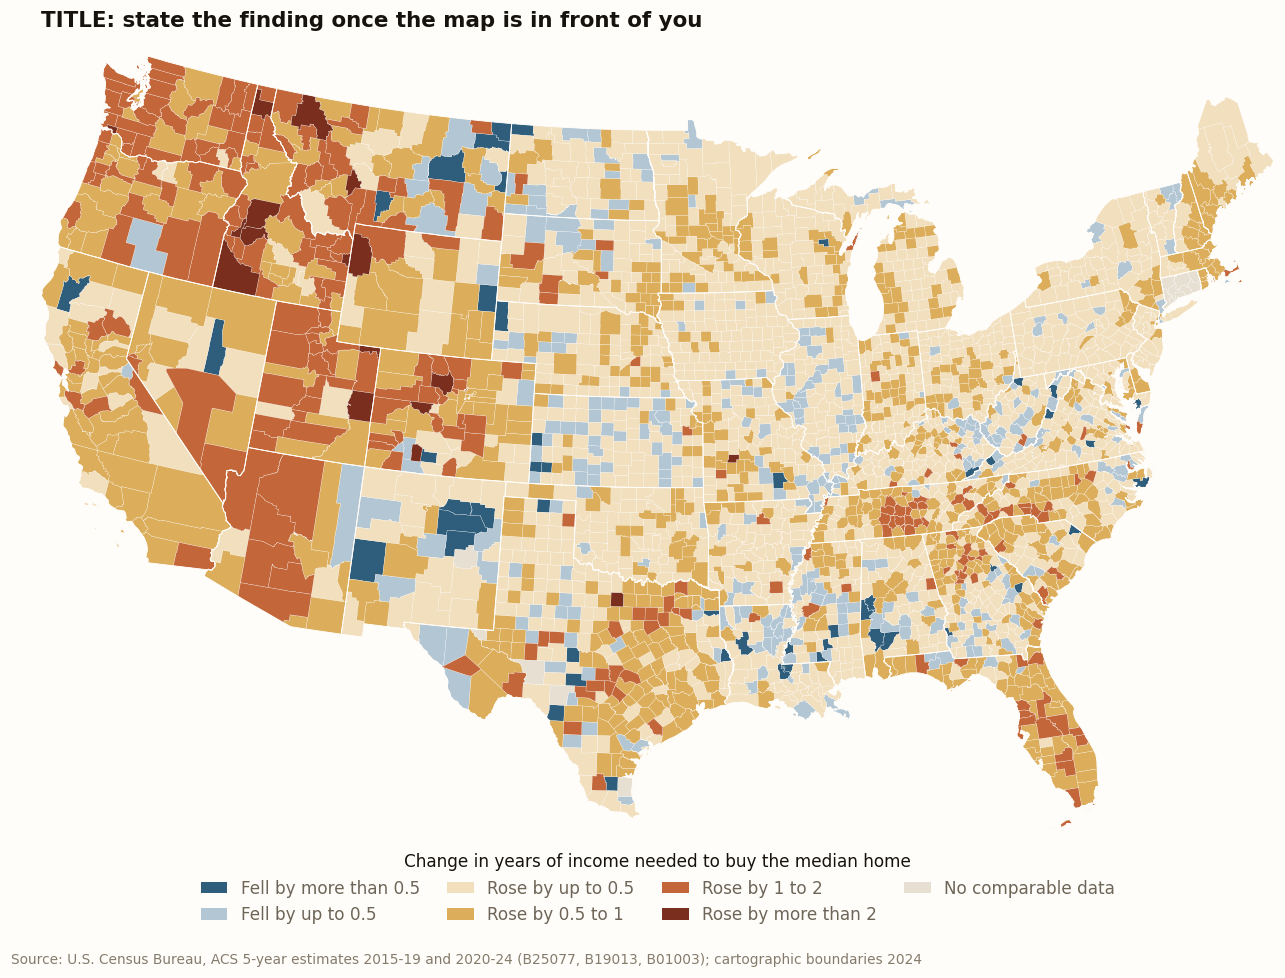

In [5]:
conus["bin"] = pd.cut(conus["d_ptir"], bins=MAP_BINS, labels=MAP_LABELS)

fig, ax = plt.subplots(figsize=(12, 8.6))
fig.subplots_adjust(left=0, right=1, top=0.95, bottom=0.13)  # map fills the width; room below for the legend
ax.set_axis_off()
ax.margins(0)
ax.grid(False)
conus.plot(column="bin", categorical=True, cmap=ListedColormap(MAP_COLORS),
           edgecolor="white", linewidth=0.15, ax=ax, legend=False,
           missing_kwds={"color": SITE["rule"], "edgecolor": "white", "linewidth": 0.15})
states.boundary.plot(ax=ax, color=SITE["paper"], linewidth=0.6)

handles = [Patch(facecolor=c, edgecolor="none", label=l) for c, l in zip(MAP_COLORS, MAP_LABELS)]
handles.append(Patch(facecolor=SITE["rule"], edgecolor="none", label="No comparable data"))
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=4, fontsize=11,
          title="Change in years of income needed to buy the median home", title_fontsize=11,
          handlelength=1.6, columnspacing=1.6, frameon=False)

ax.set_title("TITLE: state the finding once the map is in front of you", loc="left")
source_note(fig, SOURCE, y=0.0)
fig.savefig(FIGURES / "fig1_map.png", dpi=300)
plt.show()

## Fig 2 — the "why" chart

Faint dots are the counties in the analysis sample (population ≥ 50,000); the large dots
are the mean change within 20 equal-count bins of population growth. The x-axis is clipped
to the 1st–99th percentile so a handful of boom counties don't flatten the picture.

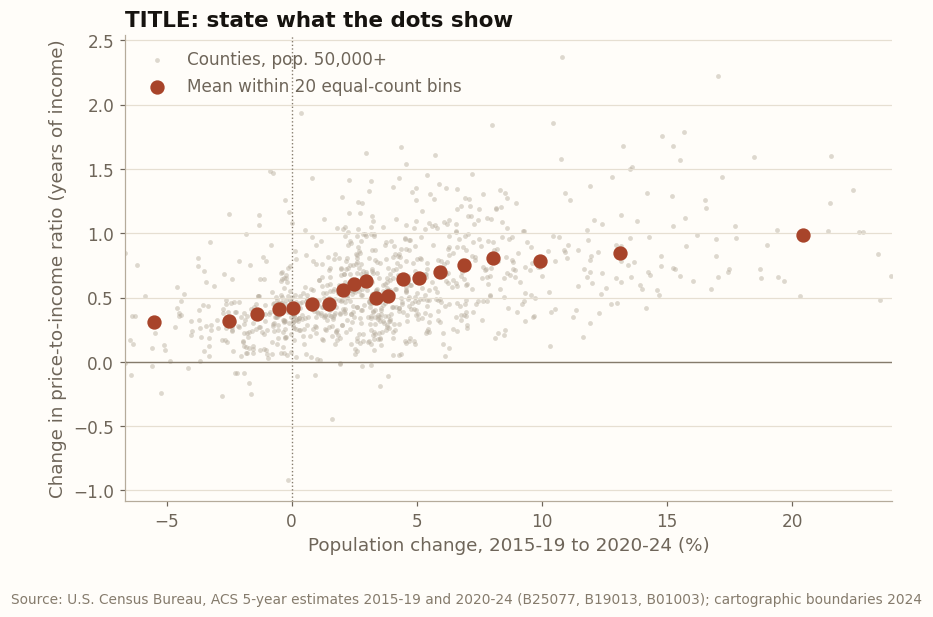

In [6]:
s = gdf.loc[gdf["in_sample"].fillna(False).astype(bool), ["pct_pop", "d_ptir"]].dropna()
bins = pd.read_csv(TABLES / "why_bins.csv")
lo, hi = s["pct_pop"].quantile([0.01, 0.99]) * 100

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(s["pct_pop"] * 100, s["d_ptir"], s=10, color=SITE["axis"], alpha=0.45, linewidths=0, label="Counties, pop. 50,000+")
ax.scatter(bins["pct_pop"] * 100, bins["d_ptir"], s=70, color=COLORS["accent"], zorder=3, label="Mean within 20 equal-count bins")
ax.axhline(0, color=SITE["faint"], linewidth=0.9)
ax.axvline(0, color=SITE["faint"], linewidth=0.9, linestyle=":")
ax.set_xlim(lo, hi)
ax.set_xlabel("Population change, 2015-19 to 2020-24 (%)")
ax.set_ylabel("Change in price-to-income ratio (years of income)")
ax.set_title("TITLE: state what the dots show", loc="left")
ax.legend(loc="upper left")
source_note(fig, SOURCE, y=-0.04)
fig.savefig(FIGURES / "fig2_why.png", dpi=300)
plt.show()